# Evaluación grupal del proyecto de minería de datos — Team Rocky

## 1. ¿Qué problema concreto aborda el proyecto, qué decisión busca apoyar y cuál es el criterio de éxito de negocio?

El proyecto estudia la **brecha de acceso a Internet fijo y móvil en las viviendas de La Paz**.
Afecta especialmente a los hogares con menor conectividad y busca apoyar la identificación de áreas y
municipios rezagados para orientar la priorización territorial de acciones de conectividad.

El éxito de negocio sería aumentar la cobertura y reducir la brecha urbano/rural mediante acciones posteriores.
**Todavía no hay una intervención evaluada ni una meta cuantitativa de negocio documentada**.
El resultado alcanzado es el diagnóstico de cobertura y los modelos predictivos, no una mejora comprobada de acceso.

In [ ]:
import base64, zlib, json, io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
FUENTE='Fuente: INE Bolivia, Censo de Población y Vivienda 2024.'

# Datos y resultados para las respuestas.
RESULTADOS = '...'

r=json.loads(zlib.decompress(base64.b64decode(RESULTADOS)))
eda,lr,arbol=r['eda'],r['logistica'],r['arbol']
def tabla(name): return pd.read_csv(io.StringIO(r['csv'][name]))


## 2. ¿Cuál es la métrica principal del proyecto y cómo se calcula?

La métrica principal de negocio es el **porcentaje de viviendas con algún Internet**:

$$Cobertura=100\frac{N(v19e\_f=1)}{N(\text{universo TIC})}.$$

Los conteos se expresan en viviendas y el resultado en %. El universo TIC incluye viviendas particulares
(tipos 1–6) con personas presentes (ocupación 0/1). El código 9 permanece en el denominador como
«sin especificar»; no se considera «No».

La acción propuesta es priorizar el diagnóstico y la ampliación de conectividad en territorios de baja cobertura
y volver a medir con un universo comparable. Es una propuesta futura. La cobertura es distinta de la exactitud del modelo.

In [ ]:
indicador=next(x for x in eda['comparacion'] if x['tipo']=='Algún internet')
cobertura=100*indicador['Sí']/indicador['universo']
display(Markdown(f"**Resultado:** {indicador['Sí']:,} / {indicador['universo']:,} × 100 = **{cobertura:.2f}%**."))
display(pd.DataFrame([{'Con Internet (viviendas)':indicador['Sí'],'Sin Internet (viviendas)':indicador['No'],
                      'Sin especificar (viviendas)':indicador['Sin especificar'],'Cobertura (%)':cobertura}]).round(2))
print(FUENTE)

**Resultado:** 748,401 / 1,069,838 × 100 = **69.95%**.

,Con Internet (viviendas),Sin Internet (viviendas),Sin especificar (viviendas),Cobertura (%)
0,748401,290940,30497,69.95


Fuente: INE Bolivia, Censo de Población y Vivienda 2024.


## 3. ¿Cuál es la unidad de análisis, de dónde provienen los datos y cuántos registros y variables tiene el conjunto utilizado?

La unidad de análisis es un **registro de vivienda**. La fuente es `Vivienda_CPV-2024.csv` del INE Bolivia,
con su diccionario oficial. Una fila no representa una persona ni un municipio.

El original nacional tiene **4.490.488 registros y 48 variables**. Para La Paz se seleccionaron
**1.334.496 registros y 16 variables**. El universo TIC contiene **1.069.838 viviendas**.
Para clasificación quedan **1.039.341 registros**, con **7 predictores y 1 target**.
Se excluyeron 264.658 registros fuera del universo TIC y 30.497 con target sin especificar.

In [ ]:
display(pd.DataFrame([
 ['Original nacional',eda['registros_nacionales'],eda['columnas_originales']],
 ['La Paz, selección del proyecto',eda['registros_lapaz'],16],
 ['Universo TIC',eda['universo_tic'],16],
 ['Clasificación: 7 predictores + target',lr['registros']['registros_target_valido'],8]
],columns=['Conjunto','Registros (viviendas)','Variables']))
print(FUENTE)

,Conjunto,Registros (viviendas),Variables
0,Original nacional,4490488,48
1,"La Paz, selección del proyecto",1334496,16
2,Universo TIC,1069838,16
3,Clasificación: 7 predictores + target,1039341,8


Fuente: INE Bolivia, Censo de Población y Vivienda 2024.


## 4. ¿Qué problemas de calidad encontraron y qué preparación aplicaron?

Se encontraron **6.737 vacíos en `v02_condocup`** y **264.658 vacíos por columna** en energía, habitaciones,
dormitorios y las cinco variables TIC indicadas en la tabla. Estos últimos corresponden al universo no aplicable.
También hay respuestas «sin especificar»: computadora 30.508, celular 30.525, Internet fijo 30.542,
móvil 30.577 y combinado 30.497. La auditoría reporta cero nulos pandas, espacios y marcadores textuales.

No se encontraron identificadores `i00` repetidos, filas duplicadas ni códigos fuera del catálogo.
Hubo **125 discrepancias** entre el indicador combinado oficial y su reconstrucción conservadora;
se conservó el indicador oficial. No se detectaron contradicciones determinadas Sí/No entre ambos.

Se filtró el universo TIC y se excluyó el target 9. En computadora y celular, 9 se trató como faltante.
Se validaron rangos numéricos, se imputaron categóricas por moda y numéricas por mediana, y se aplicó
one-hot encoding dentro del pipeline, aprendido solamente con train. Habitaciones 8 significa «8 o más»
y su uso numérico es una aproximación. La cantidad de faltantes de predictores **después del filtro de clasificación**
no está reportada en los resultados de modelado; la tabla corresponde a toda la selección de La Paz.

In [ ]:
faltantes=tabla('tablas/faltantes.csv')
display(faltantes[['variable','vacios_csv','sin_especificar','nulos_pandas']].rename(columns={
 'variable':'Variable','vacios_csv':'Vacíos (registros La Paz)',
 'sin_especificar':'Sin especificar, código 9','nulos_pandas':'Nulos pandas'}))
print(FUENTE)

,Variable,Vacíos (registros La Paz),"Sin especificar, código 9",Nulos pandas
0,idep,0,0,0
1,iprov,0,0,0
2,imun,0,0,0
3,i00,0,0,0
4,urbrur,0,0,0
5,v01_tipoviv,0,0,0
6,v02_condocup,6737,0,0
7,v09_energia,264658,0,0
8,v13_habitac,264658,0,0
9,v14_dormit,264658,0,0


Fuente: INE Bolivia, Censo de Población y Vivienda 2024.


## 5. ¿Qué resultado interesante encontraron en la exploración y qué gráfico lo demuestra?

La cobertura de algún Internet es **84,07% en el área urbana y 46,82% en el área rural**.
La brecha es **37,25 puntos porcentuales**, calculada sobre el universo TIC de cada área.
Esto permite identificar el rezago rural y orientar la priorización territorial. Es una diferencia descriptiva;
no demuestra causalidad ni explica por sí sola el costo o la calidad del servicio.

,Área,Universo (viviendas),Con Internet (viviendas),Cobertura (%)
0,Urbana,664447,558607,84.07
1,Rural,405391,189794,46.82


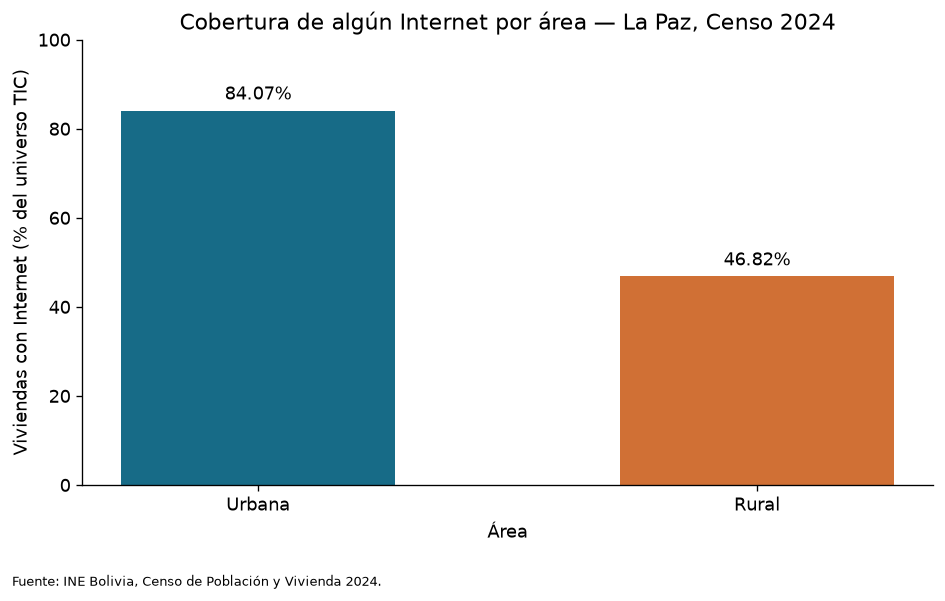

In [ ]:
areas=tabla('tablas/areas.csv')
display(areas[['area_label','universo','algun_si','pct_algun']].rename(columns={
 'area_label':'Área','universo':'Universo (viviendas)','algun_si':'Con Internet (viviendas)',
 'pct_algun':'Cobertura (%)'}).round(2))
fig,ax=plt.subplots(figsize=(8,5))
bars=ax.bar(areas.area_label,areas.pct_algun,color=['#176B87','#D07035'],width=.55)
ax.bar_label(bars,labels=[f'{v:.2f}%' for v in areas.pct_algun],padding=4)
ax.set(title='Cobertura de algún Internet por área — La Paz, Censo 2024',
       xlabel='Área',ylabel='Viviendas con Internet (% del universo TIC)',ylim=(0,100))
fig.text(.02,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.05,1,1]);plt.show()

## 6. ¿Cuál es la variable objetivo, qué clases tiene y qué modelos de clasificación utilizaron?

La variable objetivo es **`TIENE_ACCESO_INTERNET`**, construida desde `v19e_f`:
**1 = con Internet** y **0 = sin Internet**. Se excluye el código oficial 9, «sin especificar».

Se utilizaron **regresión logística y árbol de decisión de clasificación**.
La logística estima probabilidades y permite interpretar coeficientes. El árbol identifica reglas y relaciones
no lineales. Ambos usan área, tipo de vivienda, energía, computadora, celular, habitaciones y total de personas.
Se excluyen las variables de Internet para evitar fuga de información.
El árbol fue optimizado con cinco folds sobre train; sus mejores parámetros son profundidad 9,
`min_samples_leaf=5` y `min_samples_split=2`.

## 7. ¿Qué proporción de los datos usaron para entrenamiento y prueba, y cómo hicieron la separación?

La partición fue **80% entrenamiento y 20% prueba**, mediante `train_test_split`,
**`random_state=777` y estratificación por clase**: 831.472 viviendas en train y 207.869 en test.
Los dos modelos se compararon sobre la misma partición.

La imputación y la codificación se ajustaron solo con entrenamiento. La selección de parámetros del árbol
y del umbral alternativo usó exclusivamente train mediante validación cruzada. El test se reservó para evaluar.
La partición aleatoria no demuestra generalización a otros departamentos, municipios nuevos o años posteriores.

In [ ]:
assert lr['particion']==arbol['particion']
part=lr['particion']
display(pd.DataFrame({'Conjunto':['Entrenamiento','Prueba'],
                     'Viviendas':[part['train'],part['test']],
                     'Proporción prevista (%)':[80,20]}))
print('Semilla:',part['random_state'],'| Estratificación:',part['estratificada'])
print(FUENTE)

,Conjunto,Viviendas,Proporción prevista (%)
0,Entrenamiento,831472,80
1,Prueba,207869,20


Semilla: 777 | Estratificación: True
Fuente: INE Bolivia, Censo de Población y Vivienda 2024.


## 8. ¿Cuáles son las variables más importantes según el modelo y cómo determinaron su importancia?

Según la reducción ponderada de impureza del árbol, agregada por variable original, destacan
**celular (55,53%)**, **computadora (29,38%)** y **área urbana/rural (10,17%)**.
La importancia indica cuánto aporta la variable a los cortes del árbol; no es un efecto causal.

En logística, «rural» frente a «urbana» tiene coeficiente **−1,0132** y odds ratio **0,3631**:
manteniendo los otros predictores del modelo, las odds de acceso rural son aproximadamente 0,363 veces
las urbanas. Esto no equivale a una reducción de esa magnitud en la probabilidad ni establece causalidad.
Los coeficientes de variables con distintas escalas no son directamente comparables como importancia.

In [ ]:
importancias=tabla('modelado/importancia_variables_arbol_agregada.csv')
display(importancias.assign(**{'Importancia (%)':100*importancias.importancia})[
 ['variable_original','Importancia (%)']].rename(columns={'variable_original':'Variable'}).round(2))
coeficientes=tabla('modelado/coeficientes_logisticos.csv')
display(coeficientes[['descripcion','coeficiente','odds_ratio']].head(5).round(4))
print(FUENTE)

,Variable,Importancia (%)
0,v19d_celular,55.53
1,v19c_compu,29.38
2,urbrur,10.17
3,tot_pers,3.47
4,v09_energia,0.73
5,v01_tipoviv,0.54
6,v13_habitac,0.18


,descripcion,coeficiente,odds_ratio
0,19.4. Su hogar tiene: Teléfono celular: No (referencia: Sí),-3.8395,0.0215
1,"19.3. Su hogar tiene: Computadora, laptop o tablet: No (referencia: Sí)",-2.3819,0.0924
2,Área Urbana - Rural: Rural (referencia: Urbana),-1.0132,0.3631
3,1. La vivienda es: (Tipo de vivienda): Departamento (referencia: Casa),0.6642,1.9429
4,9. De donde proviene la energía eléctrica que usan en la vivienda: No tiene (referencia: Servici...,-0.3799,0.6839


Fuente: INE Bolivia, Censo de Población y Vivienda 2024.


## 9. ¿Qué desempeño obtuvo el modelo en el conjunto de prueba?

Con umbral 0,5, la logística obtuvo **80,34% de exactitud**, precisión **81,44%**, recall **94,16%**
y F1 **0,8734**. El árbol obtuvo **80,54% de exactitud**, precisión **82,37%**, recall **92,85%**
y F1 **0,8730**. Precisión, recall y F1 toman «con Internet» como clase positiva.

Para localizar viviendas sin conexión, importa reducir los **falsos positivos**: viviendas sin Internet
predichas como conectadas. El árbol tuvo 29.749 y la logística 32.114.
El proyecto ya evaluó un umbral de árbol **0,74**, seleccionado por Youden con probabilidades out-of-fold de train:
en test los falsos positivos bajaron a **8.582**, pero los falsos negativos subieron de **10.700 a 44.847**
y la exactitud bajó a **74,30%**. Es una comparación medida con un costo entre tipos de error;
no es una mejora general de todas las métricas ni de la cobertura de Internet.

,Exactitud (%),Precisión (%),Recall (%),F1,ROC-AUC
Modelo,,,,,
Regresión logística,80.3444,81.4425,94.1582,0.8734,0.8625
"Árbol, umbral 0,5",80.5411,82.3689,92.8515,0.8730,0.8652


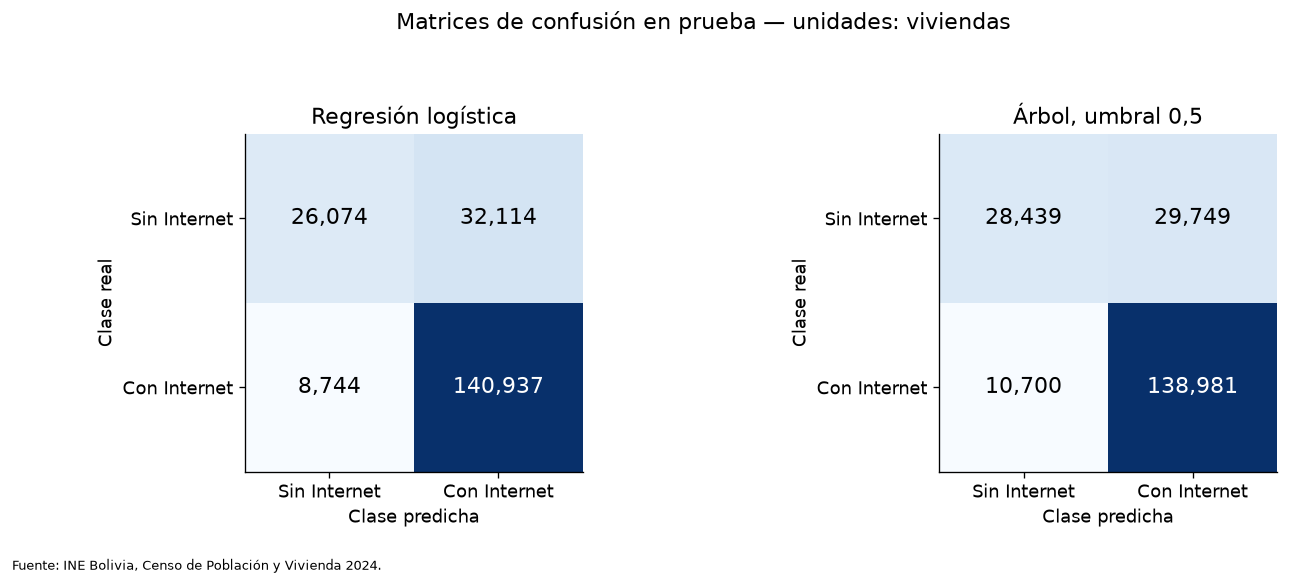

,Umbral,FP,FN,Exactitud (%)
0,0.50,29749,10700,80.5411
1,0.74,8582,44847,74.2968


Fuente: INE Bolivia, Censo de Población y Vivienda 2024.


In [ ]:
rows=[]
for nombre,modelo in [('Regresión logística',lr),('Árbol, umbral 0,5',arbol)]:
 m=modelo['metricas']['test'];cm=np.array(modelo['matriz_confusion_test']['matriz'])
 tn,fp,fn,tp=cm.ravel()
 assert np.isclose((tn+tp)/cm.sum(),m['accuracy'])
 assert np.isclose(tp/(tp+fp),m['precision'])
 assert np.isclose(tp/(tp+fn),m['recall'])
 assert np.isclose(2*tp/(2*tp+fp+fn),m['f1'])
 rows.append({'Modelo':nombre,'Exactitud (%)':100*m['accuracy'],'Precisión (%)':100*m['precision'],
              'Recall (%)':100*m['recall'],'F1':m['f1'],'ROC-AUC':m['roc_auc']})
display(pd.DataFrame(rows).set_index('Modelo').round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for ax,(nombre,modelo) in zip(axes,[('Regresión logística',lr),('Árbol, umbral 0,5',arbol)]):
 cm=np.array(modelo['matriz_confusion_test']['matriz']);ax.imshow(cm,cmap='Blues')
 for (i,j),v in np.ndenumerate(cm):ax.text(j,i,f'{v:,}',ha='center',va='center',
                             color='white' if v>cm.max()/2 else 'black',fontsize=13)
 ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Sin Internet','Con Internet'],
        yticklabels=['Sin Internet','Con Internet'],xlabel='Clase predicha',ylabel='Clase real',title=nombre)
fig.suptitle('Matrices de confusión en prueba — unidades: viviendas')
fig.text(.02,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.05,1,.93]);plt.show()
alternativo=arbol['seleccion_umbral_roc']
display(pd.DataFrame([
 {'Umbral':.5,'FP':arbol['matriz_confusion_test']['fp'],'FN':arbol['matriz_confusion_test']['fn'],
  'Exactitud (%)':100*arbol['metricas']['test']['accuracy']},
 {'Umbral':alternativo['umbral'],'FP':alternativo['matriz_confusion_test']['fp'],
  'FN':alternativo['matriz_confusion_test']['fn'],'Exactitud (%)':100*alternativo['metricas_test']['accuracy']}
]).round(4))
print(''+FUENTE)

## 10. ¿Qué visualización permite entender cómo toma decisiones el modelo?

El gráfico de coeficientes permite distinguir asociaciones positivas y negativas en la logística;
la tabla de la pregunta 8 identifica las categorías de referencia. Un coeficiente negativo reduce las log-odds
de acceso manteniendo los otros predictores.

También se muestra **el gráfico del árbol, niveles 0–3**. El modelo completo tiene profundidad 9,
665 nodos y 333 hojas; el gráfico parcial no muestra todas las rutas. Una ruta completa, extraída del modelo, aparece en la tabla siguiente: parte de **tener celular y computadora**, continúa por **área rural**,
tener energía y las otras condiciones indicadas, y termina en una hoja que predice **con Internet**.
Los indicadores one-hot se interpretan así: `variable_2 ≤ 0,5` significa que no pertenece a la categoría 2.
La ruta explica la decisión del modelo, sin atribuir causalidad.

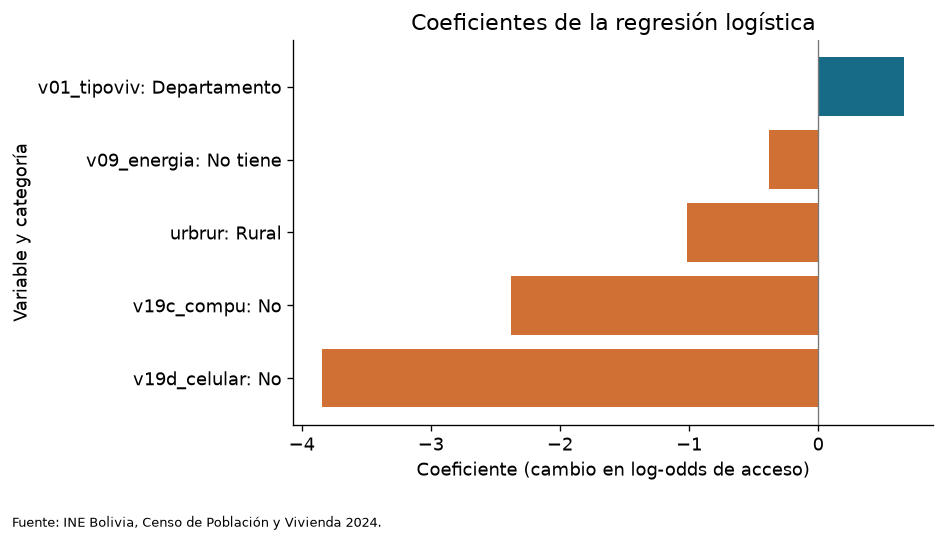

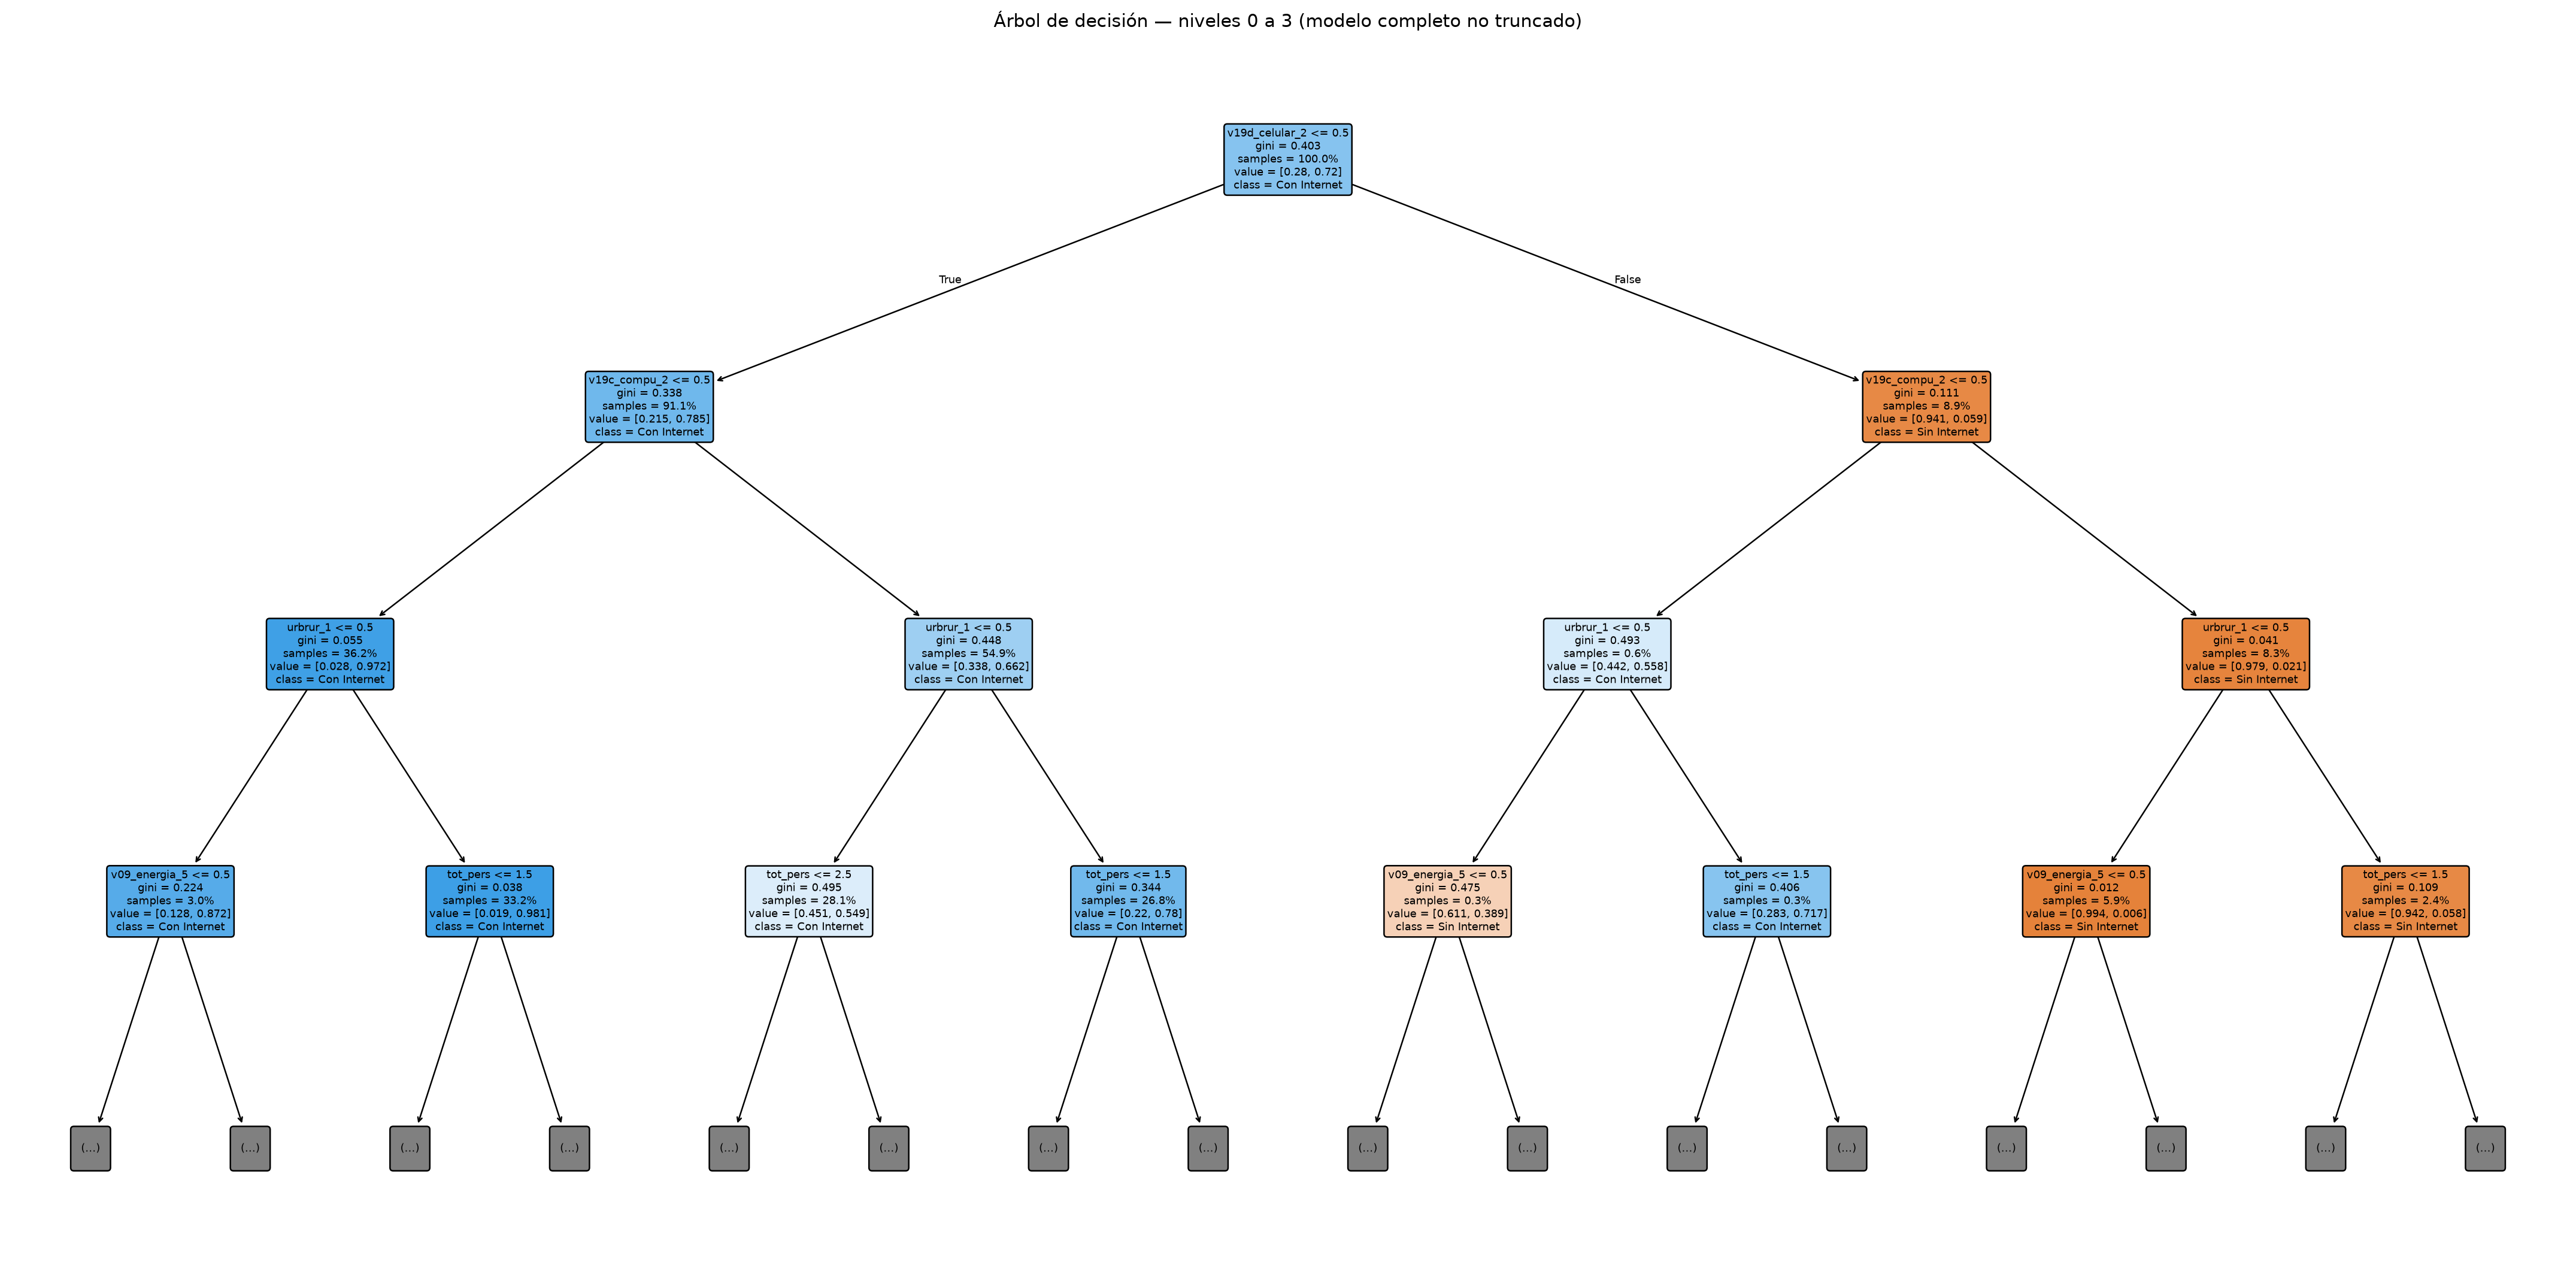

,Nodo,Variable,Condición,Umbral
0,0,v19d_celular_2,≤,0.5
1,1,v19c_compu_2,≤,0.5
2,2,urbrur_1,≤,0.5
3,3,v09_energia_5,≤,0.5
4,4,v13_habitac,≤,4.5
5,5,v01_tipoviv_3,≤,0.5
6,6,tot_pers,≤,1.5
7,7,v01_tipoviv_4,≤,0.5
8,8,v01_tipoviv_5,≤,0.5


**Final de la ruta:** hoja 9, con 5,082 viviendas de entrenamiento. Probabilidad estimada de acceso: **85.18%**; con umbral 0,5 predice **con Internet**. La ruta corresponde al modelo de clasificación.

In [ ]:
top=coeficientes.head(5).sort_values('coeficiente')
etiquetas=[f'{x.variable_original}: {x.categoria}' for x in top.itertuples()]
fig,ax=plt.subplots(figsize=(8,4.5))
ax.barh(etiquetas,top.coeficiente,color=['#D07035' if v<0 else '#176B87' for v in top.coeficiente])
ax.axvline(0,color='#777',linewidth=.8)
ax.set(title='Coeficientes de la regresión logística',
       xlabel='Coeficiente (cambio en log-odds de acceso)',ylabel='Variable y categoría')
fig.text(.02,.01,FUENTE,fontsize=8);fig.tight_layout(rect=[0,.06,1,1]);plt.show()
display(Image(data=base64.b64decode(r['grafico_arbol'])))
display(pd.DataFrame(r['ruta']))
hoja=r['hoja']
display(Markdown(f"**Final de la ruta:** hoja {hoja['nodo']}, con {hoja['viviendas_train']:,} viviendas de entrenamiento. "
                 f"Probabilidad estimada de acceso: **{hoja['probabilidad_con_internet']:.2%}**; "
                 "con umbral 0,5 predice **con Internet**. La ruta corresponde al modelo de clasificación."))